In [1]:
import numpy as np
import matplotlib.pyplot as plt 
import pandas as pd  
import seaborn as sns 
from sklearn.datasets import load_iris

In [2]:
iris = load_iris()  # 从Sklearn库中加载iris数据集
X = iris.data  # 提取数据特征矩阵
y = iris.target  # 提取标签

In [3]:
feature_names = ['Sepal length, $X_1$', 'Sepal width, $X_2$', 'Petal length, $X_3$', 'Petal width, $X_4$']

In [4]:
X_df = pd.DataFrame(X, columns=feature_names)  # 将X转换为带列名的数据框

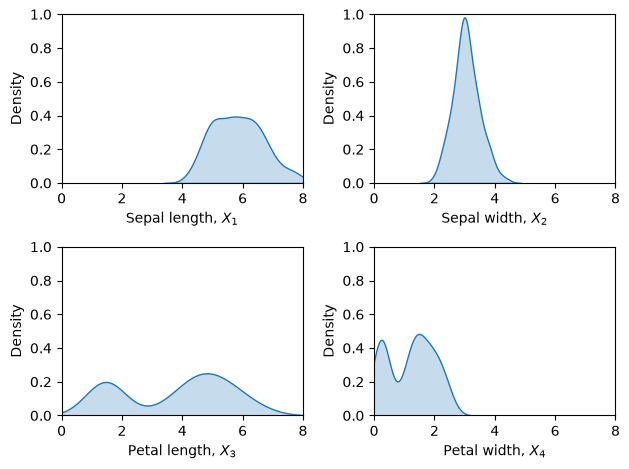

In [5]:
fig, axes = plt.subplots(2, 2)  # 创建2x2子图布局

# 绘制每个特征的核密度估计图，并设置x轴和y轴的显示范围
sns.kdeplot(data=X_df, fill=True, x=feature_names[0], ax=axes[0][0])  # 特征1的核密度图
axes[0][0].set_xlim([0, 8]); axes[0][0].set_ylim([0, 1])

sns.kdeplot(data=X_df, fill=True, x=feature_names[1], ax=axes[0][1])  # 特征2的核密度图
axes[0][1].set_xlim([0, 8]); axes[0][1].set_ylim([0, 1])

sns.kdeplot(data=X_df, fill=True, x=feature_names[2], ax=axes[1][0])  # 特征3的核密度图
axes[1][0].set_xlim([0, 8]); axes[1][0].set_ylim([0, 1])

sns.kdeplot(data=X_df, fill=True, x=feature_names[3], ax=axes[1][1])  # 特征4的核密度图
axes[1][1].set_xlim([0, 8]); axes[1][1].set_ylim([0, 1])

plt.tight_layout()  # 紧凑布局

In [6]:
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt 
import pandas as pd  
from sklearn.datasets import load_iris

In [7]:
iris = load_iris()  # 从Sklearn库中加载iris数据集

X = iris.data  # 提取数据特征矩阵
y = iris.target  # 提取标签

In [8]:
feature_names = ['Sepal length, $X_1$', 'Sepal width, $X_2$', 'Petal length, $X_3$', 'Petal width, $X_4$']

In [9]:
## 将特征矩阵X转换为数据框格式
X_df = pd.DataFrame(X, columns=feature_names)  # 创建带特征列的数据框

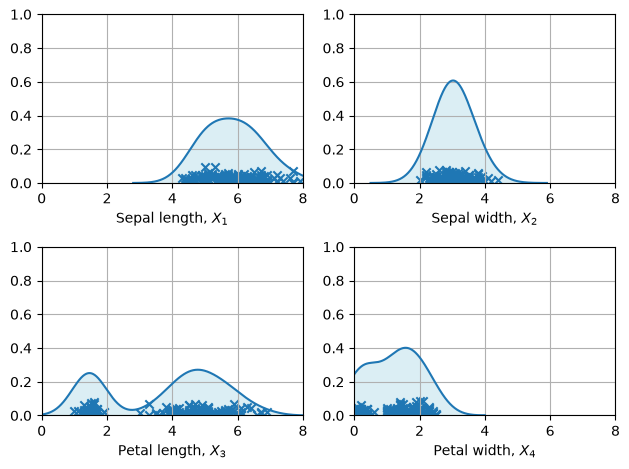

In [14]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2)  # 创建2x2子图布局
axs = [ax1, ax2, ax3, ax4]  # 定义各子图的轴对象

for name, ax in zip(feature_names, axs):
    df = X_df[name]  # 选择每个特征列的数据
    KDE = sm.nonparametric.KDEUnivariate(df)  # 创建核密度估计对象
    KDE.fit(bw=0.5)  # 拟合核密度估计，设置带宽为0.5

    # 绘制核密度估计图
    ax.fill_between(KDE.support, KDE.density, facecolor='#DBEEF4')  # 填充KDE密度
    #执行fit之后自动生成的x和y值
    ax.plot(KDE.support, KDE.density)  # 绘制密度曲线
    ax.scatter(df, 0.03 * np.abs(np.random.randn(df.size)), marker='x')  # 数据散点图

    ax.grid()  # 显示网格
    ax.autoscale(enable=True, axis='x', tight=True)  # x轴自动缩放
    ax.autoscale(enable=True, axis='y', tight=True)  # y轴自动缩放
    ax.set_ylim([0, 1])  # 设置y轴范围
    ax.set_xlim([0, 8])  # 设置x轴范围
    ax.set_xlabel(name)  # 设置x轴标签为特征名称

plt.tight_layout()  # 紧凑布局

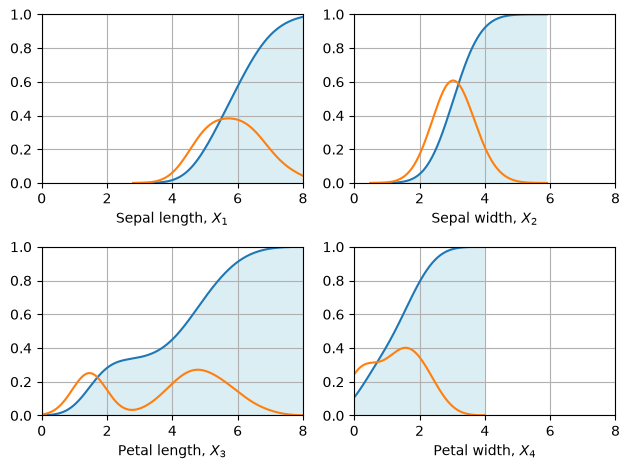

In [15]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2)  # 创建2x2子图布局
axs = [ax1, ax2, ax3, ax4]  # 定义各子图的轴对象

for name, ax in zip(feature_names, axs):
    df = X_df[name]  # 选择每个特征列的数据
    KDE = sm.nonparametric.KDEUnivariate(df)  # 创建核密度估计对象
    KDE.fit(bw=0.5)  # 拟合核密度估计，设置带宽为0.5

    # 绘制累积分布函数 (CDF) 和密度图
    ax.fill_between(KDE.support, KDE.cdf, facecolor='#DBEEF4')  # 填充累积分布函数
    ax.plot(KDE.support, KDE.cdf)  # 绘制CDF曲线
    ax.plot(KDE.support, KDE.density)  # 绘制密度曲线

    ax.grid()  # 显示网格
    ax.autoscale(enable=True, axis='x', tight=True)  # x轴自动缩放
    ax.autoscale(enable=True, axis='y', tight=True)  # y轴自动缩放
    ax.set_ylim([0, 1])  # 设置y轴范围
    ax.set_xlim([0, 8])  # 设置x轴范围
    ax.set_xlabel(name)  # 设置x轴标签为特征名称

plt.tight_layout()  # 紧凑布局

In [17]:
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt 
from statsmodels.nonparametric.kde import kernel_switch
#给予迭代器切片的能力
from itertools import islice

In [18]:
list(kernel_switch.keys())  # 列出所有可用的核函数选项

['gau', 'epa', 'uni', 'tri', 'biw', 'triw', 'cos', 'cos2', 'tric']

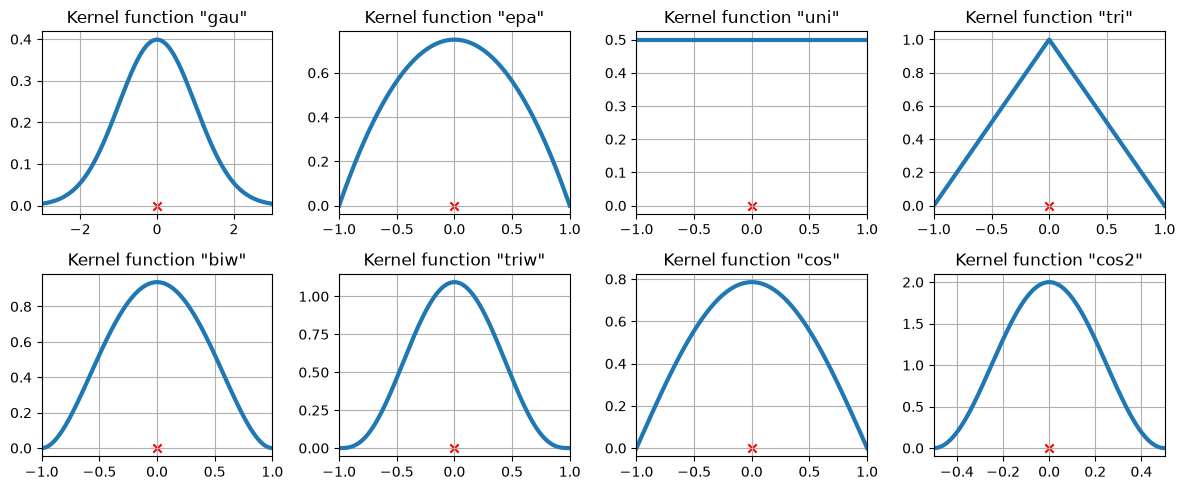

In [19]:
fig = plt.figure(figsize=(12, 5))  # 设置图形大小

# 遍历前8种核函数选项
for i, (ker_name, ker_class) in enumerate(islice(kernel_switch.items(), 8)):
    
    kernel = ker_class()  # 初始化核对象
    
    # 取样域值
    #左边为真,返回左边的值,如果左边为假,右边为真才返回右边的值
        #左右为False,才返回False
    domain = kernel.domain or [-3, 3]  # 若无定义，默认域为[-3, 3]
    x_vals = np.linspace(*domain, num=2**10)  # 在域内生成点
    y_vals = kernel(x_vals)  # 计算核函数值

    # 创建子图，设置标题
    ax = fig.add_subplot(2, 4, i + 1)
    ax.set_title('Kernel function "{}"'.format(ker_name))  # 设置标题
    ax.plot(x_vals, y_vals, lw=3, label='{}'.format(ker_name))  # 绘制核函数曲线
    ax.scatter([0], [0], marker='x', color='red')  # 标注中心点
    plt.grid(True, zorder=-5)  # 显示网格
    ax.set_xlim(domain)  # 设置x轴范围
    
plt.tight_layout()  # 紧凑布局

In [20]:
data = [-3, -2, 0, 2, 2.5, 3, 4]  # 样本数据
#单变量核密度估计器
kde = sm.nonparametric.KDEUnivariate(data)  # 创建核密度估计对象

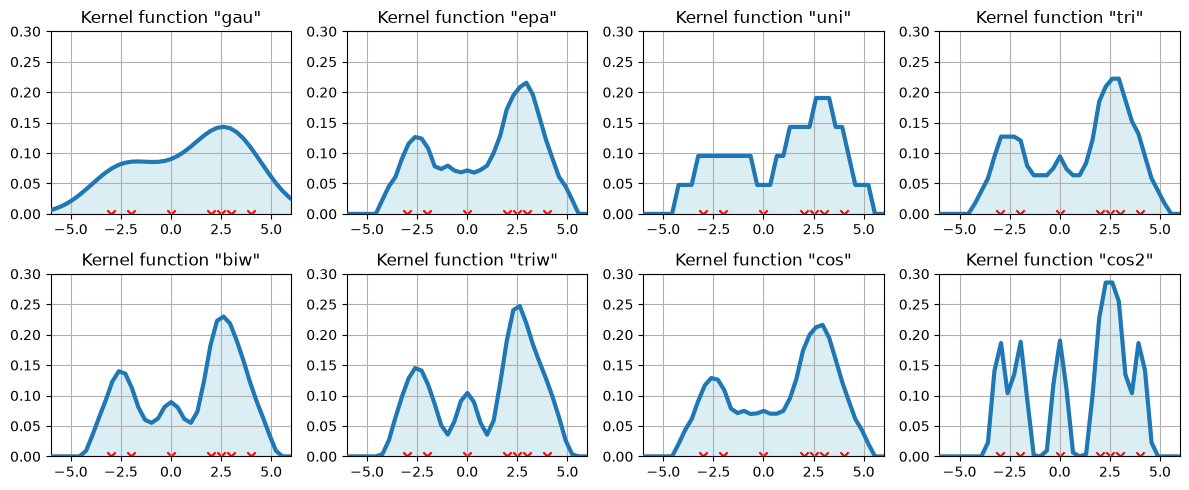

In [21]:
## 创建图形窗口
fig = plt.figure(figsize=(12, 5))  # 设置图形大小

## 遍历前8种核函数选项
for i, kernel in enumerate(islice(kernel_switch.keys(), 8)):
    
    ax = fig.add_subplot(2, 4, i + 1)  # 创建子图
    ax.set_title('Kernel function "{}"'.format(kernel))  # 设置标题
    
    # 拟合模型（估计密度）
    kde.fit(kernel=kernel, fft=False, bw=1.5)  # 指定核和带宽，进行密度估计
    
    ax.fill_between(kde.support, kde.density, facecolor='#DBEEF4')  # 填充密度估计区域
    ax.plot(kde.support, kde.density, lw=3, label='KDE from samples', zorder=10)  # 绘制密度曲线
    ax.scatter(data, np.zeros_like(data), marker='x', color='red')  # 绘制样本点
    plt.grid()  # 显示网格
    ax.set_xlim([-6, 6])  # 设置x轴范围
    ax.set_ylim([0, 0.3])  # 设置y轴范围
    
plt.tight_layout()  # 紧凑布局

In [22]:
import numpy as np
import scipy.stats as st
import statsmodels.api as sm
import matplotlib.pyplot as plt 
import pandas as pd  
from sklearn.datasets import load_iris

In [23]:
iris = load_iris()

X = iris.data  # 获取数据
x = X[:, 0]  # 提取第一个特征 (花萼长度)
y = X[:, 1]  # 提取第二个特征 (花萼宽度)

xmin, xmax = 4, 8  # 设置x轴范围
ymin, ymax = 1, 5  # 设置y轴范围

In [24]:
xx, yy = np.mgrid[xmin:xmax:100j, ymin:ymax:100j]  # 创建x和y的网格
positions = np.vstack([xx.ravel(), yy.ravel()])  # 将网格位置合并为二维数组

In [25]:
values = np.vstack([x, y])  # 将特征合并为二维数组

In [26]:
kernel = st.gaussian_kde(values)  # 使用高斯核函数进行密度估计

In [27]:
PDF_xy = np.reshape(kernel(positions).T, xx.shape)  # 重塑密度估计结果为网格形状

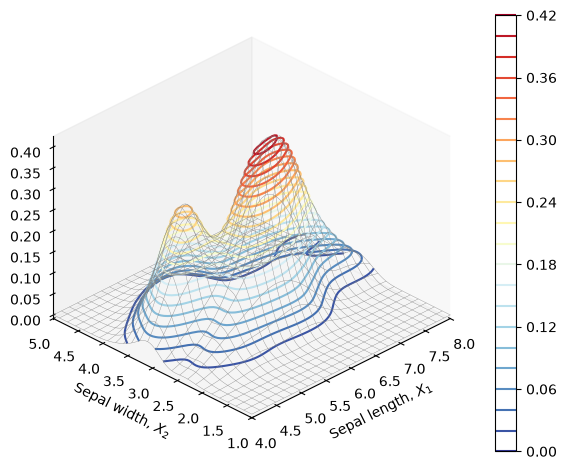

In [28]:
fig, ax = plt.subplots(subplot_kw={'projection': '3d'})  # 创建3D图形

ax.plot_wireframe(xx, yy, PDF_xy, 
                  rstride=4, cstride=4,  # 设置线框步长
                  color=[0.5, 0.5, 0.5],  # 设置线框颜色
                  linewidth=0.25)  # 设置线框宽度

colorbar = ax.contour(xx, yy, PDF_xy, 20, cmap='RdYlBu_r')  # 绘制等高线
fig.colorbar(colorbar, ax=ax)  # 添加颜色条

ax.set_xlabel(r'Sepal length, $X_1$')  # 设置x轴标签
ax.set_ylabel(r'Sepal width, $X_2$')  # 设置y轴标签
ax.set_zlabel(r'$f_{X1,X2}(x_1,x_2)$')  # 设置z轴标签

ax.set_proj_type('ortho')  # 设置正交投影
ax.view_init(azim=-135, elev=30)  # 设置视角
ax.grid(False)  # 隐藏网格
ax.set_xlim(xx.min(), xx.max())  # 设置x轴范围
ax.set_ylim(yy.min(), yy.max())  # 设置y轴范围
plt.tight_layout()  # 紧凑布局

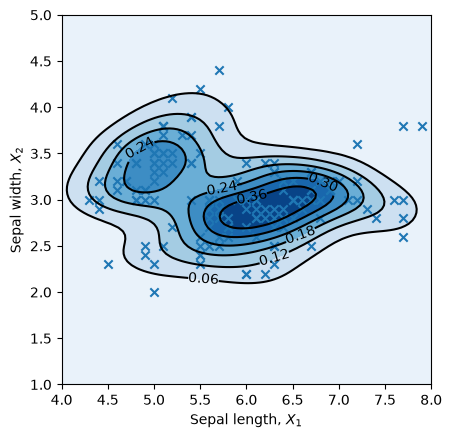

In [29]:
fig = plt.figure()
ax = fig.gca()  # 获取当前子图
ax.set_xlim(xmin, xmax)  # 设置x轴范围
ax.set_ylim(ymin, ymax)  # 设置y轴范围

cfset = ax.contourf(xx, yy, PDF_xy, cmap='Blues')  # 填充等高线图
cset = ax.contour(xx, yy, PDF_xy, colors='k')  # 绘制等高线
plt.scatter(x, y, marker='x')  # 在等高线图上绘制散点

ax.clabel(cset, inline=1, fontsize=10)  # 标签等高线
ax.set_xlabel(r'Sepal length, $X_1$')  # 设置x轴标签
ax.set_ylabel(r'Sepal width, $X_2$')  # 设置y轴标签
plt.gca().set_aspect('equal', adjustable='box')  # 设置坐标轴比例

In [30]:
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt 
import pandas as pd  
from sklearn.datasets import load_iris
import scipy.stats as st
import seaborn as sns  # 导入seaborn库

In [31]:
# 加载iris数据集
iris_sns = sns.load_dataset("iris")  # 从Seaborn加载iris数据集

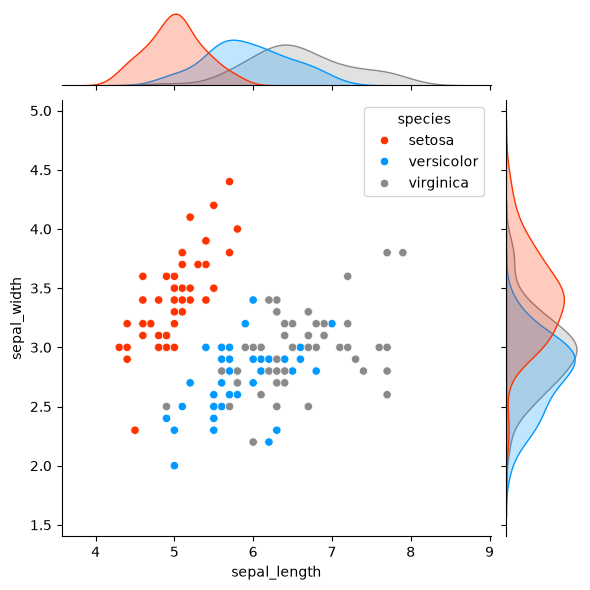

In [32]:
# 绘制花萼长度和宽度的散点图
sns.jointplot(data=iris_sns, x="sepal_length", y="sepal_width", hue='species',
              palette={'setosa': '#FF3300', 'versicolor': '#0099FF', 'virginica': '#8A8A8A'})

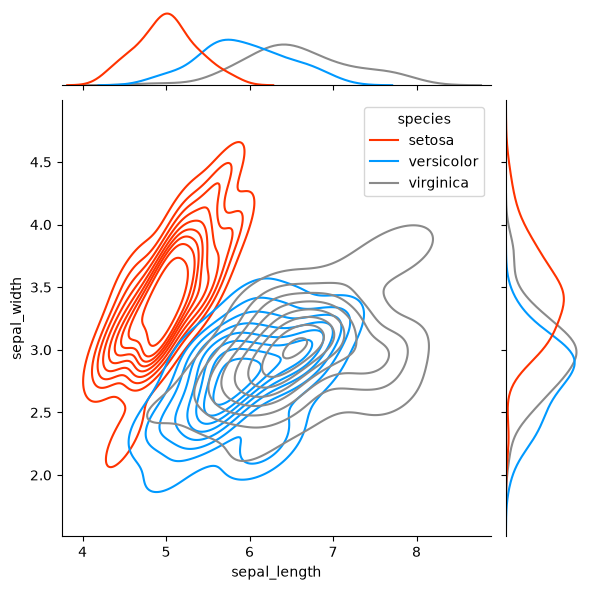

In [33]:
# 绘制花萼长度和宽度的核密度估计图
sns.jointplot(data=iris_sns, x="sepal_length", y="sepal_width", hue='species',
              kind="kde",  # 使用核密度估计图
              palette={'setosa': '#FF3300', 'versicolor': '#0099FF', 'virginica': '#8A8A8A'})